In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
df=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
df.head

,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,...,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529
3,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,619.9937,596.2667,281.4671,282.0251,281.1446,423.2008,438.1189,406.9265,164.189,2.222
4,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,...,610.3878,586.3428,276.8312,277.5799,276.2557,417.3453,432.7454,400.7629,163.064,2.157
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84355,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,...,29.4343,35.8025,9.6232,8.1477,11.1791,26.9260,25.8335,28.0762,-0.001,-0.126
84356,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,...,29.0008,35.3848,9.4943,8.0242,11.0440,26.5634,25.4456,27.7401,-0.001,-0.103
84357,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,...,28.5670,34.9669,9.3653,7.9008,10.9090,26.2007,25.0576,27.4040,-0.001,-0.109
84358,326.0,876,2,WLF,WF,876.0,4.0,Country/Area,957.0,Wallis and Futuna Islands,...,28.3501,34.5488,9.2681,7.8390,10.7740,25.9376,24.8635,27.0678,-0.001,-0.168


In [87]:
# Convert year to numeric
df["Time"] = pd.to_numeric(df["Time"], errors="coerce")

# Convert demographic variables to numeric
df["TFR"] = pd.to_numeric(df["TFR"], errors="coerce")

df["PopGrowthRate"] = pd.to_numeric(
    df["PopGrowthRate"], errors="coerce"
)

# Remove rows without country codes or years
df = df.dropna(subset=["ISO3_code", "Time"])

# Keep the relevant demographic columns
df = df[
    [
        "ISO3_code",
        "Location",
        "Time",
        "Variant",
        "TFR",
        "PopGrowthRate"
    ]
]

print(df.head())

      ISO3_code Location  Time Variant     TFR  PopGrowthRate
44384       BDI  Burundi  1950  Medium  6.9229          2.272
44385       BDI  Burundi  1951  Medium  6.9139          2.185
44386       BDI  Burundi  1952  Medium  6.9002          2.111
44387       BDI  Burundi  1953  Medium  6.9146          2.039
44388       BDI  Burundi  1954  Medium  6.9170          2.028


In [88]:
if "Medium" in df["Variant"].dropna().unique():
    df = df[df["Variant"] == "Medium"].copy()

In [89]:
conflicts = {
    "Bosnia and Herzegovina": {
        "code": "BIH",
        "start": 1992,
        "end": 1995
    },

    "Rwanda": {
        "code": "RWA",
        "start": 1990,
        "end": 1994
    },

    "Sri Lanka": {
        "code": "LKA",
        "start": 1983,
        "end": 2009
    },

    "Syria": {
        "code": "SYR",
        "start": 2011,
        "end": None
    },

    "Ukraine": {
        "code": "UKR",
        "start": 2014,
        "end": None
    }
}

In [90]:
ukraine_2022 = {
    "Ukraine (Full-scale invasion)": {
        "code": "UKR",
        "start": 2022,
        "end": None
    }
}

In [91]:
def prepare_event_data(df, country_name, conflict):

    country_code = conflict["code"]
    war_start = conflict["start"]

    # Select the country
    country_data = df[
        df["ISO3_code"] == country_code
    ].copy()

    # Keep five years before and five years after war begins
    country_data = country_data[
        (country_data["Time"] >= war_start - 5) &
        (country_data["Time"] <= war_start + 5)
    ].copy()

    # Convert calendar year into relative year
    country_data["RelativeYear"] = (
        country_data["Time"] - war_start
    )

    # Sort chronologically
    country_data = country_data.sort_values("RelativeYear")

    # Calculate the baseline: one year before war
    baseline = country_data[
        country_data["RelativeYear"] == -1
    ]

    if baseline.empty:
        print(f"Missing baseline data for {country_name}")
        return None

    baseline_tfr = baseline["TFR"].iloc[0]
    baseline_growth = baseline["PopGrowthRate"].iloc[0]

    # Calculate change relative to the year before war
    country_data["TFR_Change"] = (
        country_data["TFR"] - baseline_tfr
    )

    country_data["Growth_Change"] = (
        country_data["PopGrowthRate"] - baseline_growth
    )

    return country_data

In [92]:
import os
import matplotlib.pyplot as plt

def generate_country_graph(country_name, conflict, df):

    data = prepare_event_data(df, country_name, conflict)

    if data is None or data.empty:
        print(f"No data available for {country_name}")
        return

    # Create output folder
    os.makedirs("war_demographic_graphs", exist_ok=True)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Fertility change
    axes[0].plot(
        data["RelativeYear"],
        data["TFR_Change"],
        marker="o",
        linewidth=2
    )

    axes[0].axhline(y=0, linestyle="--", color="gray")
    axes[0].axvline(x=0, linestyle="--", color="red",
                    label="War begins")

    axes[0].set_title(f"{country_name}: Fertility Change")
    axes[0].set_xlabel("Years Relative to War")
    axes[0].set_ylabel("Change in Fertility Rate")
    axes[0].set_xticks(range(-5, 6))
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Population growth change
    axes[1].plot(
        data["RelativeYear"],
        data["Growth_Change"],
        marker="o",
        linewidth=2
    )

    axes[1].axhline(y=0, linestyle="--", color="gray")
    axes[1].axvline(x=0, linestyle="--", color="red",
                    label="War begins")

    axes[1].set_title(f"{country_name}: Population Growth Change")
    axes[1].set_xlabel("Years Relative to War")
    axes[1].set_ylabel("Change in Population Growth Rate")
    axes[1].set_xticks(range(-5, 6))
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(
        f"Demographic Changes Around War: {country_name}",
        fontsize=14
    )

    fig.tight_layout()

    # Create a safe filename
    filename = (
        country_name.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    filepath = os.path.join(
        "war_demographic_graphs",
        filename + ".png"
    )

    # Save figure
    fig.savefig(filepath, dpi=300, bbox_inches="tight")

    print(f"Saved: {filepath}")

    plt.show()
    plt.close(fig)

Saved: war_demographic_graphs/Bosnia_and_Herzegovina.png


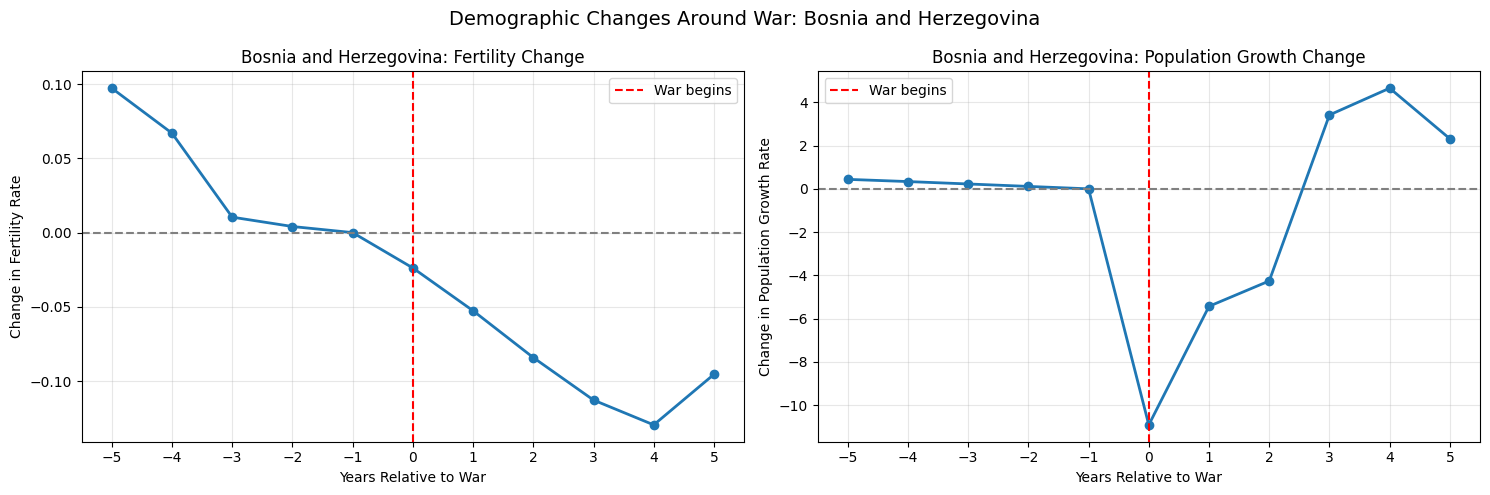

Saved: war_demographic_graphs/Rwanda.png


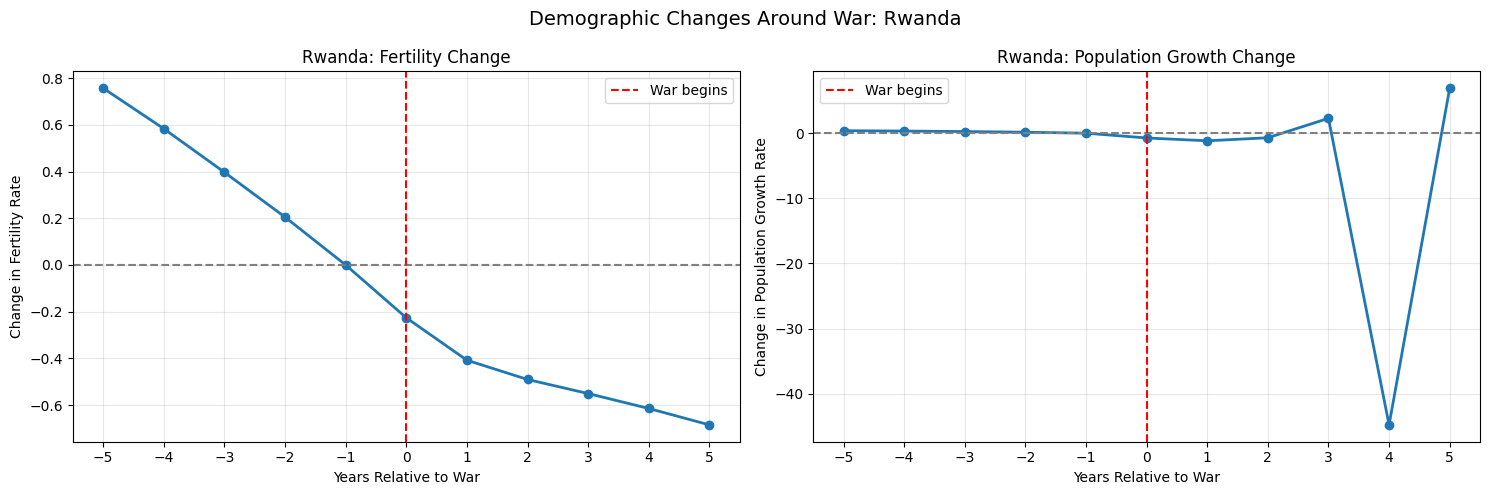

Saved: war_demographic_graphs/Sri_Lanka.png


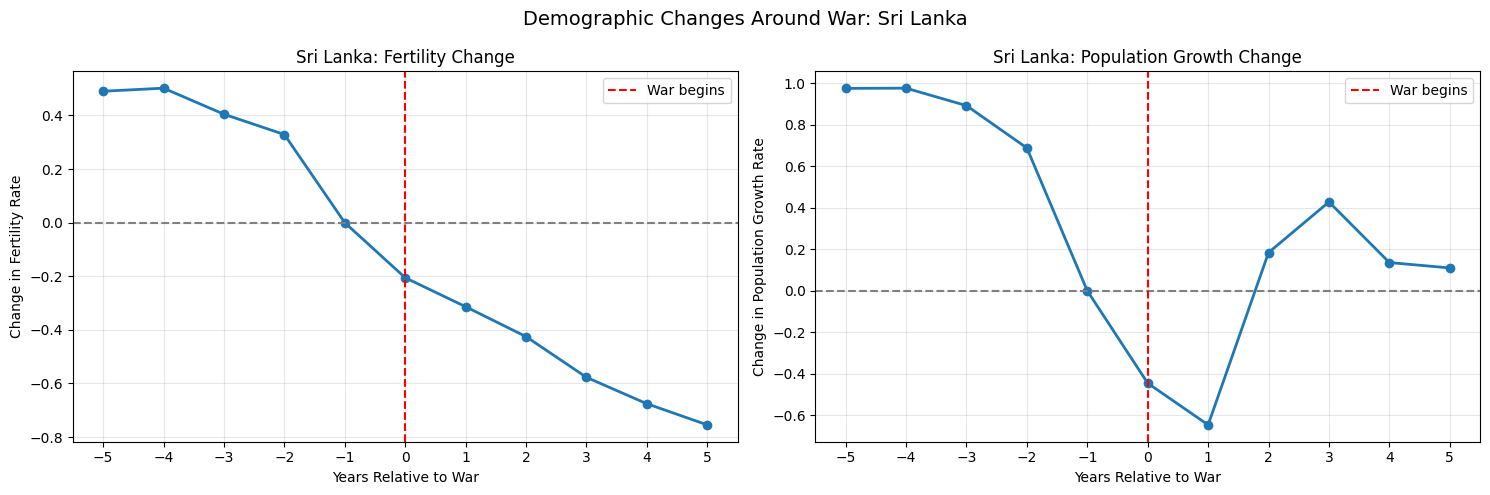

Saved: war_demographic_graphs/Syria.png


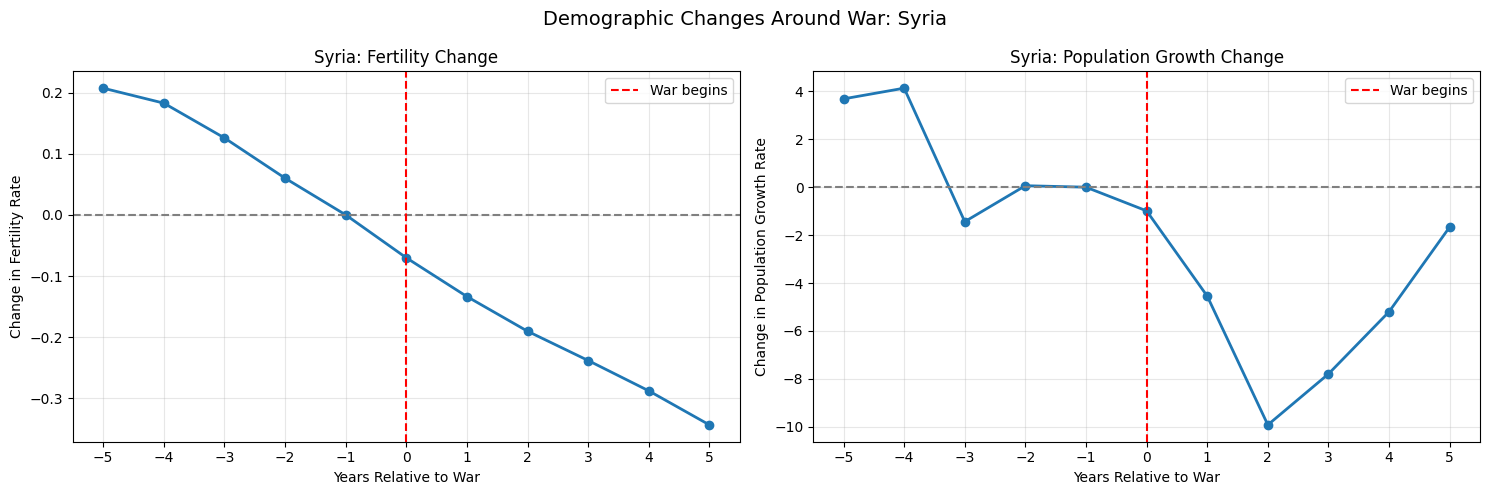

Saved: war_demographic_graphs/Ukraine.png


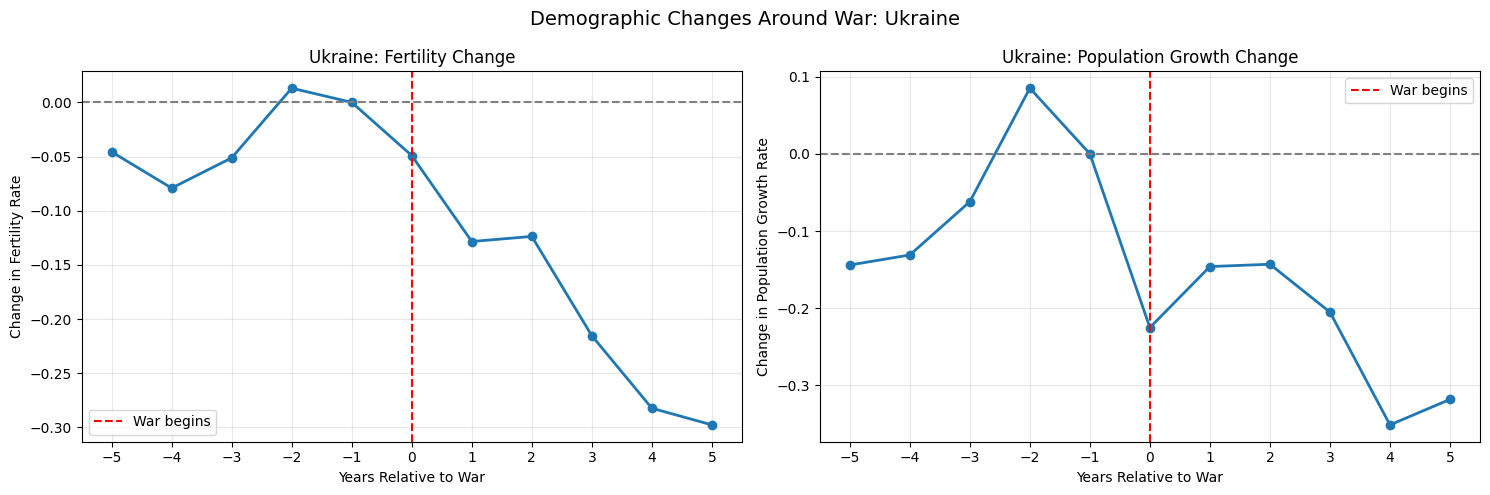

Saved: war_demographic_graphs/Ukraine_Full_scale_invasion.png


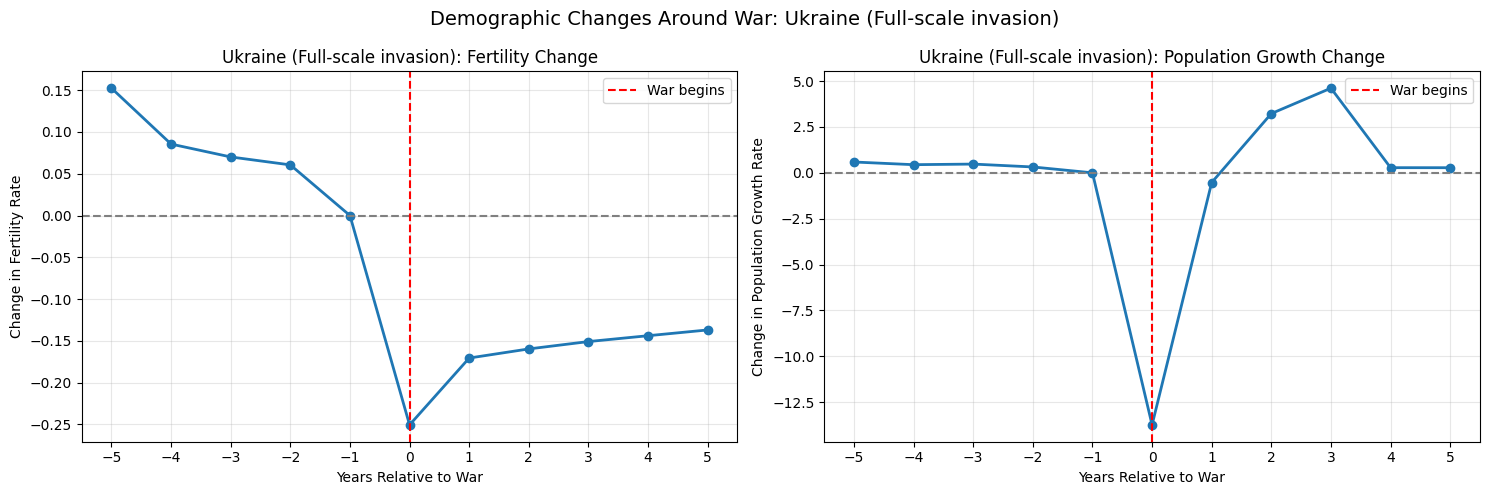


Finished generating all graphs!


In [93]:
# Generate and save all country graphs

for country_name, conflict in conflicts.items():

    generate_country_graph(country_name, conflict, df)


# Generate Ukraine's 2022 analysis separately

for country_name, conflict in ukraine_2022.items():

    generate_country_graph(country_name, conflict, df)


print("\nFinished generating all graphs!")

In [94]:
import os

folder = "war_demographic_graphs"

print("Current working directory:", os.getcwd())

print("\nSaved PNG files:")

for file in os.listdir(folder):
    if file.endswith(".png"):
        print(file)

Current working directory: /Users/mo7ammedsharaki/programming/DATA QUEST/Population-Growth-Migration-and-Urban-Pressure

Saved PNG files:
Ukraine.png
Rwanda.png
Syria.png
Ukraine_Full_scale_invasion.png
Sri_Lanka.png
Bosnia_and_Herzegovina.png


# previous work


In [97]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean visualization defaults
sns.set_theme(style="whitegrid")


def analyze_demographic_drivers(
    df: pd.DataFrame, countries: list, variant: str = "Medium"
):
    """Decomposes population growth into Natural Change Rate and Net Migration Rate,

    and compares Total Fertility Rate across target Middle Eastern countries.
    """
    # Filter dataset for requested locations and baseline variant
    sub_df = df[
        (df["Location"].isin(countries)) & (df["Variant"] == variant)
    ].copy()

    # Calculate Natural Change Rate if not already explicit (CBR - CDR)
    if "NatChangeRT" not in sub_df.columns:
        sub_df["NatChangeRT"] = sub_df["CBR"] - sub_df["CDR"]

    # 1. Summary Archetype Profiler
    latest_year = sub_df["Time"].max()
    latest_data = sub_df[sub_df["Time"] == latest_year].set_index("Location")

    print(f"=== Demographic Archetype Summary ({latest_year}) ===")
    for country in countries:
        if country in latest_data.index:
            row = latest_data.loc[country]
            tfr = row["TFR"]
            nat_rate = row["NatChangeRT"]
            cnmr = row["CNMR"]
            growth = row["PopGrowthRate"]

            # Archetype classification logic
            if cnmr > nat_rate and cnmr > 5:
                archetype = "Migration-Driven Growth (GCC Model)"
            elif tfr < 2.1 and nat_rate < 8:
                archetype = "Advanced Demographic Transition (Aging/Slowing)"
            else:
                archetype = "Natural Expansion (High Birth Rate)"

            print(f"\nLocation: {country}")
            print(f"  - Archetype: {archetype}")
            print(
                f"  - TFR: {tfr:.2f} | Natural Growth Rate: {nat_rate:.1f}/1k | Net Migration Rate: {cnmr:.1f}/1k"
            )
            print(f"  - Total Population Growth Rate: {growth:.2f}%")

    # 2. Time-Series Trajectory Visualization
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    # Plot Total Fertility Rate (TFR) against Replacement Level (2.1)
    for country in countries:
        c_data = sub_df[sub_df["Location"] == country].sort_values("Time")
        axes[0].plot(
            c_data["Time"], c_data["TFR"], label=country, linewidth=2.5
        )

    axes[0].axhline(
        2.1,
        color="black",
        linestyle="--",
        alpha=0.7,
        label="Replacement Level (2.1)",
    )
    axes[0].set_title(
        "Fertility Trajectories: Total Fertility Rate (TFR) Over Time",
        fontsize=13,
        fontweight="bold",
    )
    axes[0].set_ylabel("Children per Woman (TFR)", fontsize=11)
    axes[0].legend(loc="upper right")

    # Plot Decomposed Growth Drivers for Turkey as a Case Study
    turkey_data = sub_df[sub_df["Location"] == "Türkiye"].sort_values("Time")
    if not turkey_data.empty:
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["NatChangeRT"],
            label="Natural Growth Rate (CBR - CDR)",
            color="#1f77b4",
            linewidth=2.5,
        )
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["CNMR"],
            label="Crude Net Migration Rate (CNMR)",
            color="#2ca02c",
            linewidth=2.5,
            linestyle="--",
        )
        axes[1].plot(
            turkey_data["Time"],
            turkey_data["PopGrowthRate"],
            label="Total Population Growth Rate (%)",
            color="#d62728",
            linewidth=2,
            linestyle=":",
        )
        axes[1].axhline(0, color="gray", linewidth=1)
        axes[1].set_title(
            "Türkiye Case Study: Natural Change vs. Net Migration Dynamics",
            fontsize=13,
            fontweight="bold",
        )
        axes[1].set_ylabel("Rate per 1,000 / Growth %", fontsize=11)
        axes[1].set_xlabel("Year", fontsize=11)
        axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()

# Example invocation (Replace 'df' with your loaded UN WPP DataFrame):
analyze_demographic_drivers(df, countries=['Türkiye', 'United Arab Emirates', 'Egypt', 'Saudi Arabia'])

KeyError: 'CBR'